In [1]:
library(keras)
library(tensorflow)


In [2]:
dataset_dir <- "/kaggle/input/breast-cancer-detection"

In [3]:
set.seed(42)
tensorflow::tf$random$set_seed(42)

In [4]:
train_dir <- "/kaggle/input/breast-cancer-detection/train"
valid_dir <- "/kaggle/input/breast-cancer-detection/valid"
test_dir  <- "/kaggle/input/breast-cancer-detection/test"

In [5]:
train_0_count <- length(list.files(file.path(train_dir, "0")))
train_1_count <- length(list.files(file.path(train_dir, "1")))
total_train <- train_0_count + train_1_count
weight_for_0 <- (1 / train_0_count) * (total_train / 2.0)
weight_for_1 <- (1 / train_1_count) * (total_train / 2.0)
class_weights <- list("0" = weight_for_0, "1" = weight_for_1)

In [6]:
img_size <- 224
batch_size <- 32

In [7]:
train_gen <- image_data_generator(
  rotation_range = 20,
  width_shift_range = 0.15,
  height_shift_range = 0.15,
  zoom_range = 0.15,
  horizontal_flip = TRUE
)

valid_gen <- image_data_generator()

In [8]:
conv_base <- application_resnet50_v2(
  weights = "imagenet", include_top = FALSE, input_shape = c(img_size, img_size, 3)
)

In [9]:
train_generator <- flow_images_from_directory(
  directory = train_dir, generator = train_gen, target_size = c(img_size, img_size),
  batch_size = batch_size, class_mode = "binary", color_mode = "rgb"
)
validation_generator <- flow_images_from_directory(
  directory = valid_dir, generator = valid_gen, target_size = c(img_size, img_size),
  batch_size = batch_size, class_mode = "binary", color_mode = "rgb"
)

In [10]:
input_tensor <- conv_base$input
preprocessed_tensor <- input_tensor %>% layer_lambda(f = function(x) (x / 127.5) - 1)
base_output <- conv_base(preprocessed_tensor)
output_tensor <- base_output %>%
  layer_global_average_pooling_2d() %>%
  layer_dense(units = 128, activation = "relu") %>%
  layer_dropout(rate = 0.5) %>%
  layer_dense(units = 1, activation = "sigmoid")
model <- keras_model(inputs = input_tensor, outputs = output_tensor)

In [11]:
freeze_weights(conv_base)
model %>% compile(optimizer = optimizer_adam(learning_rate = 0.001), loss = "binary_crossentropy", metrics = c("accuracy"))
history_warmup <- model %>% fit(
  train_generator, epochs = 10, validation_data = validation_generator, class_weight = class_weights
)

In [12]:
unfreeze_weights(conv_base, from = "conv4_block1_1_conv")
model %>% compile(optimizer = optimizer_adam(learning_rate = 1e-5), loss = "binary_crossentropy", metrics = c("accuracy"))
callback_early_stopping <- callback_early_stopping(monitor = "val_loss", patience = 10, restore_best_weights = TRUE) # More patience
callback_model_checkpoint <- callback_model_checkpoint(
  filepath = "best_resnet_model_weights.h5",
  monitor = "val_loss",
  save_best_only = TRUE,
  save_weights_only = TRUE,
  verbose = 1
)


In [13]:
history_finetune <- model %>% fit(
  train_generator,
  epochs = 50,
  initial_epoch = 10,
  validation_data = validation_generator,
  class_weight = class_weights,
  callbacks = list(callback_early_stopping, callback_model_checkpoint),
  workers = 1,
  use_multiprocessing = FALSE
)

In [14]:
str(history_finetune)


List of 2
 $ params :List of 3
  ..$ verbose: int 1
  ..$ epochs : int 50
  ..$ steps  : int 75
 $ metrics:List of 4
  ..$ loss        : num [1:24] 0.703 0.666 0.65 0.644 0.636 ...
  ..$ accuracy    : num [1:24] 0.614 0.589 0.591 0.602 0.63 ...
  ..$ val_loss    : num [1:24] 0.657 0.66 0.646 0.64 0.636 ...
  ..$ val_accuracy: num [1:24] 0.576 0.575 0.604 0.6 0.616 ...
 - attr(*, "class")= chr "keras_training_history"


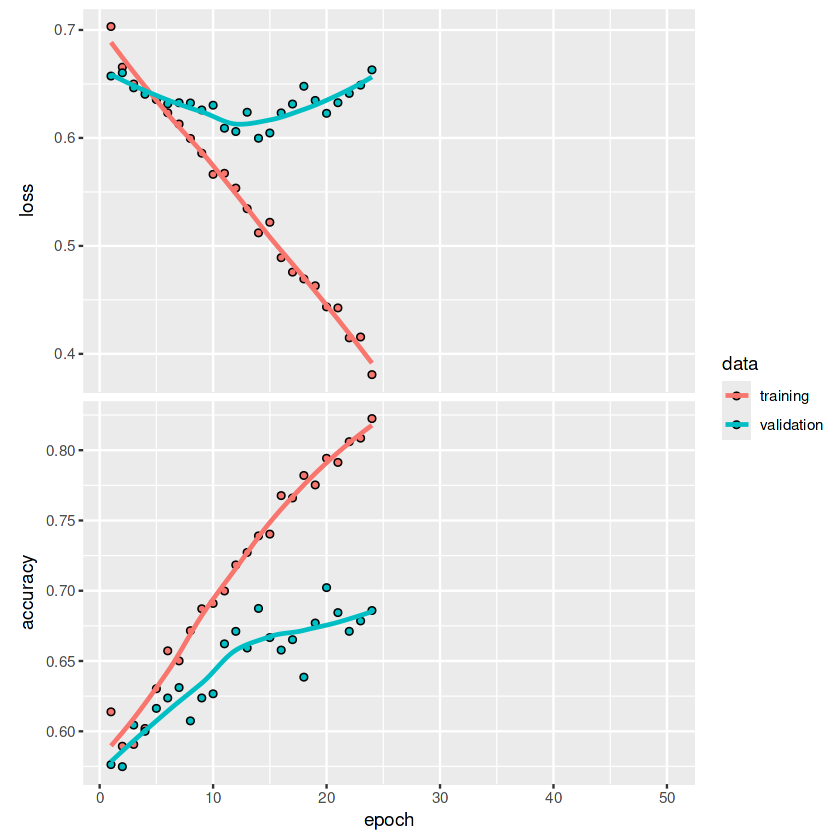

In [15]:
plot(history_finetune)


In [16]:
model %>% load_model_weights_hdf5("best_resnet_model_weights.h5")

In [17]:
df <- as.data.frame(history_finetune$metrics)
df$epoch <- 1:nrow(df)

# saving to kaggle
write.csv(df, "/kaggle/working/training_history.csv", row.names = FALSE)

In [18]:
best_epoch <- which.max(df$val_accuracy)
df[best_epoch, ]
best_epoch <- which.min(df$val_loss)
df[best_epoch, ]


,loss,accuracy,val_loss,val_accuracy,epoch
,<dbl>,<dbl>,<dbl>,<dbl>,<int>
20,0.4434974,0.7942665,0.6228029,0.7022222,20


,loss,accuracy,val_loss,val_accuracy,epoch
,<dbl>,<dbl>,<dbl>,<dbl>,<int>
14,0.5120946,0.7390388,0.5997056,0.6874074,14


In [19]:
test_generator <- flow_images_from_directory(
  directory = test_dir, generator = valid_gen, target_size = c(img_size, img_size),
  batch_size = batch_size, class_mode = "binary", color_mode = "rgb", shuffle = FALSE
)
evaluation_results <- model %>% evaluate(test_generator)
cat("\nFinal Test Loss:", evaluation_results[1], "\n")
cat("Final Test Accuracy:", evaluation_results[2], "\n")


Final Test Loss: 0.6101719 
Final Test Accuracy: 0.6517857 


Setting levels: control = 0, case = 1

Setting direction: controls < cases



AUC: 0.727 
Optimal Threshold: 0.451 
Sensitivity (opt): 0.727 
Specificity (opt): 0.649 
         Actual
Predicted   0   1
        0 135  35
        1  73  93
Confusion Matrix and Statistics

          Reference
Prediction   0   1
         0 135  35
         1  73  93
                                          
               Accuracy : 0.6786          
                 95% CI : (0.6257, 0.7282)
    No Information Rate : 0.619           
    P-Value [Acc > NIR] : 0.0135432       
                                          
                  Kappa : 0.3553          
                                          
 Mcnemar's Test P-Value : 0.0003704       
                                          
            Sensitivity : 0.7266          
            Specificity : 0.6490          
         Pos Pred Value : 0.5602          
         Neg Pred Value : 0.7941          
             Prevalence : 0.3810          
         Detection Rate : 0.2768          
   Detection Prevalence : 0.4940          

Warning message in geom_point(aes(x = 1 - opt_specificity, y = opt_sensitivity), :
“All aesthetics have length 1, but the data has 337 rows.
ℹ Please consider using `annotate()` or provide this layer with data containing
  a single row.”


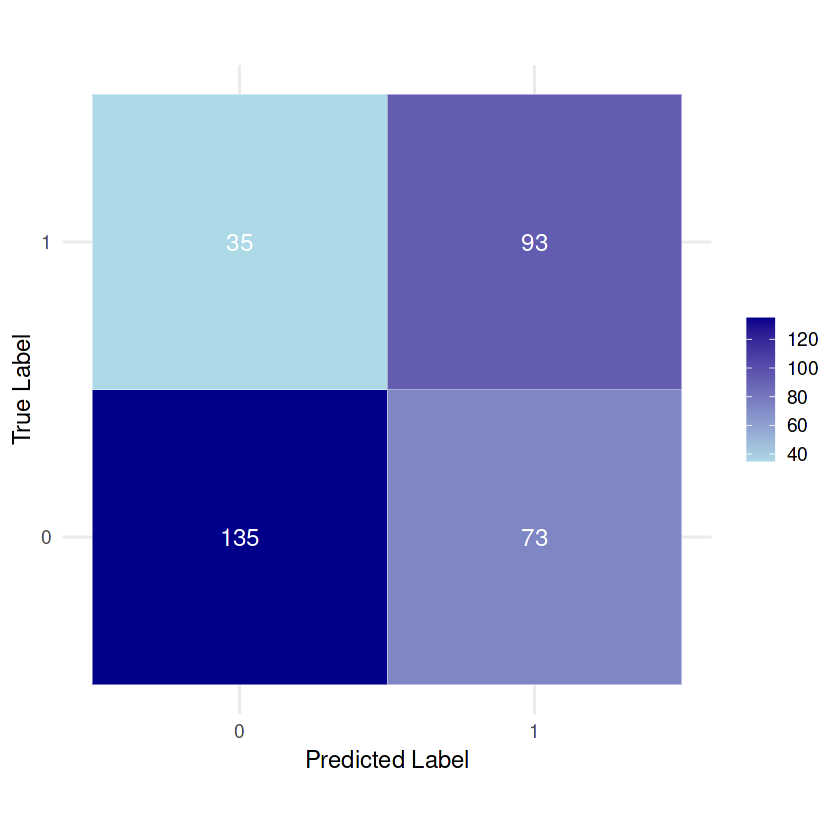

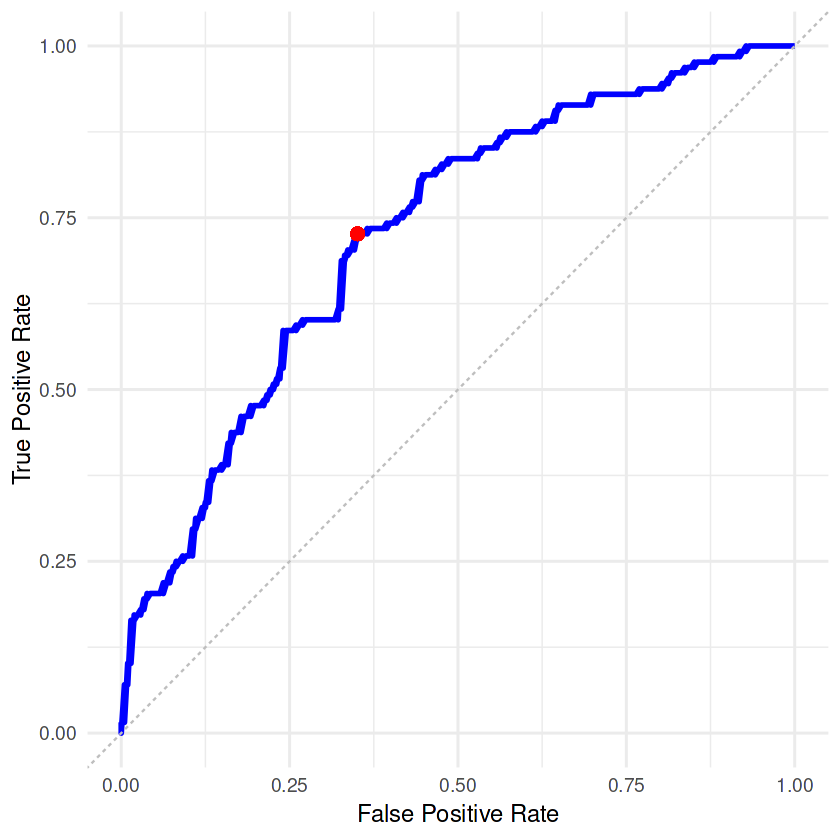

In [25]:
library(keras)
library(ggplot2)
library(pROC)
library(caret)

# Predict on test set
pred_probs <- model %>% predict(
  test_generator,
  steps = ceiling(test_generator$n / test_generator$batch_size)
)
pred_probs <- as.vector(pred_probs)

# True labels
true_labels <- test_generator$classes

# ROC , AUC
roc_obj <- roc(response = true_labels, predictor = pred_probs)
auc_val <- auc(roc_obj)

#  Optimal threshold
roc_coords <- coords(roc_obj, x = "best", best.method = "youden",
                     ret = c("threshold", "sensitivity", "specificity"))
opt_threshold   <- roc_coords["threshold"][[1]]
opt_sensitivity <- roc_coords["sensitivity"][[1]]
opt_specificity <- roc_coords["specificity"][[1]]

cat("AUC:", round(auc_val, 3), "\n")
cat("Optimal Threshold:", round(opt_threshold, 3), "\n")
cat("Sensitivity (opt):", round(opt_sensitivity, 3), "\n")
cat("Specificity (opt):", round(opt_specificity, 3), "\n")

# Predicting classes
pred_classes <- ifelse(pred_probs >= opt_threshold, 1, 0)

#  Confusion Matrix
cm <- table(Predicted = pred_classes, Actual = true_labels)
print(cm)

#  Heatmap
cm_df <- as.data.frame(cm)
colnames(cm_df) <- c("Predicted", "Actual", "Freq")

ggplot(cm_df, aes(x = Predicted, y = Actual, fill = Freq)) +
  geom_tile(color = "white") +
  geom_text(aes(label = Freq), color = "white", size = 5) +
  scale_fill_gradient(low = "lightblue", high = "darkblue", name = NULL) +
  labs(x = "Predicted Label", y = "True Label") +
  theme_minimal(base_size = 14) +
  coord_fixed()

# 8. Metrics 
conf_matrix <- confusionMatrix(
  factor(pred_classes, levels = c(0, 1)),
  factor(true_labels, levels = c(0, 1)),
  positive = "1"
)
print(conf_matrix)

acc  <- conf_matrix$overall["Accuracy"]
prec <- conf_matrix$byClass["Precision"]
rec  <- conf_matrix$byClass["Recall"]
f1   <- conf_matrix$byClass["F1"]

cat("Accuracy:", round(acc, 3), "\n")
cat("Precision:", round(prec, 3), "\n")
cat("Recall (Sensitivity):", round(rec, 3), "\n")
cat("F1 Score:", round(f1, 3), "\n")

# 9. ROC Plot 
roc_df <- data.frame(
  FPR = 1 - roc_obj$specificities,
  TPR = roc_obj$sensitivities
)

ggplot(roc_df, aes(x = FPR, y = TPR)) +
  geom_line(color = "blue", size = 1.2) +
  geom_abline(linetype = "dashed", color = "gray") +
  geom_point(aes(x = 1 - opt_specificity, y = opt_sensitivity),
             color = "red", size = 3) +
  labs(x = "False Positive Rate", y = "True Positive Rate") +
  theme_minimal(base_size = 14)


         Actual
Predicted   0   1
        0 135  35
        1  73  93


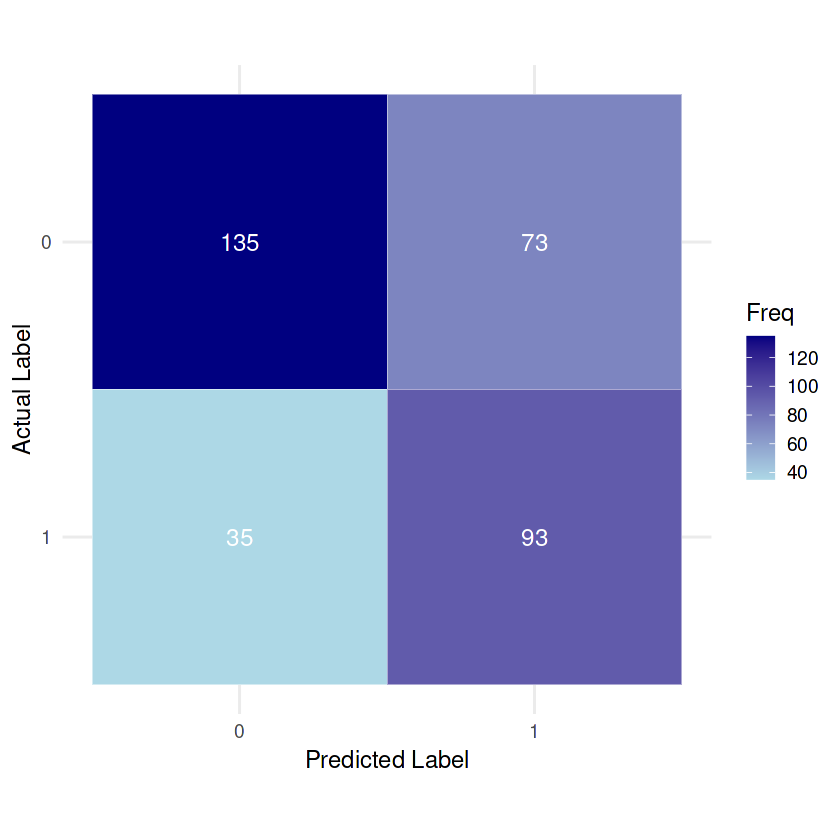

In [28]:
# Confusion Matrix - with 0 on top to main consistency
cm <- table(Predicted = pred_classes, Actual = true_labels)
print(cm)



cm_df <- as.data.frame(cm)
colnames(cm_df) <- c("Predicted", "Actual", "Freq")

cm_df$Actual <- factor(as.character(cm_df$Actual), levels = c("0", "1"))       # Y-axis
cm_df$Predicted <- factor(as.character(cm_df$Predicted), levels = c("0", "1")) # X-axis

ggplot(cm_df, aes(x = Predicted, y = Actual, fill = Freq)) +
  geom_tile(color = "white") +
  geom_text(aes(label = Freq), color = "white", size = 5) +
  scale_fill_gradient(low = "lightblue", high = "navy") +
  scale_y_discrete(limits = rev(levels(cm_df$Actual))) +  # <-- THIS IS THE FIX
  labs(x = "Predicted Label", y = "Actual Label") +
  theme_minimal(base_size = 14) +
  coord_fixed()


In [31]:
# Extract metrics from history object
df <- data.frame(
  epoch = 1:length(history_finetune$metrics$loss),
  loss = history_finetune$metrics$loss,
  accuracy = history_finetune$metrics$accuracy,
  val_loss = history_finetune$metrics$val_loss,
  val_accuracy = history_finetune$metrics$val_accuracy
)


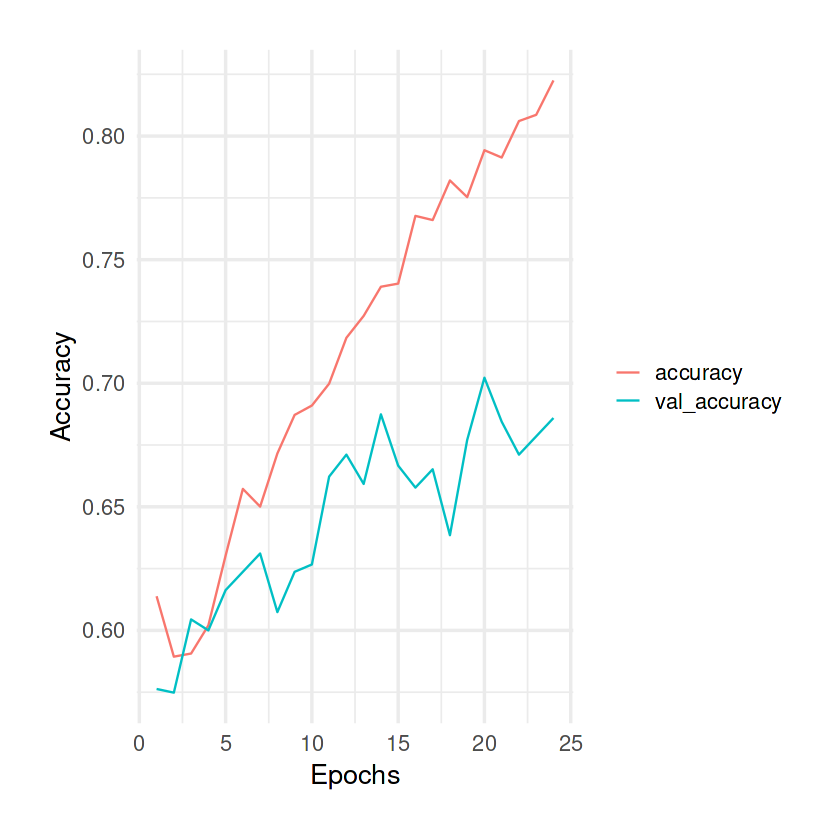

In [46]:
library(ggplot2)
library(tidyr)

df_acc <- pivot_longer(df, cols = c(accuracy, val_accuracy),
                       names_to = "Type", values_to = "Accuracy")

ggplot(df_acc, aes(x = epoch, y = Accuracy, color = Type)) +
  geom_line(size = 0.5) +
  labs(x = "Epochs", y = "Accuracy") +
  theme_minimal(base_size = 16) +
  theme(
    legend.title = element_blank(),    
    plot.title = element_blank(),      
    plot.margin = margin(30, 30, 30, 30)
  )


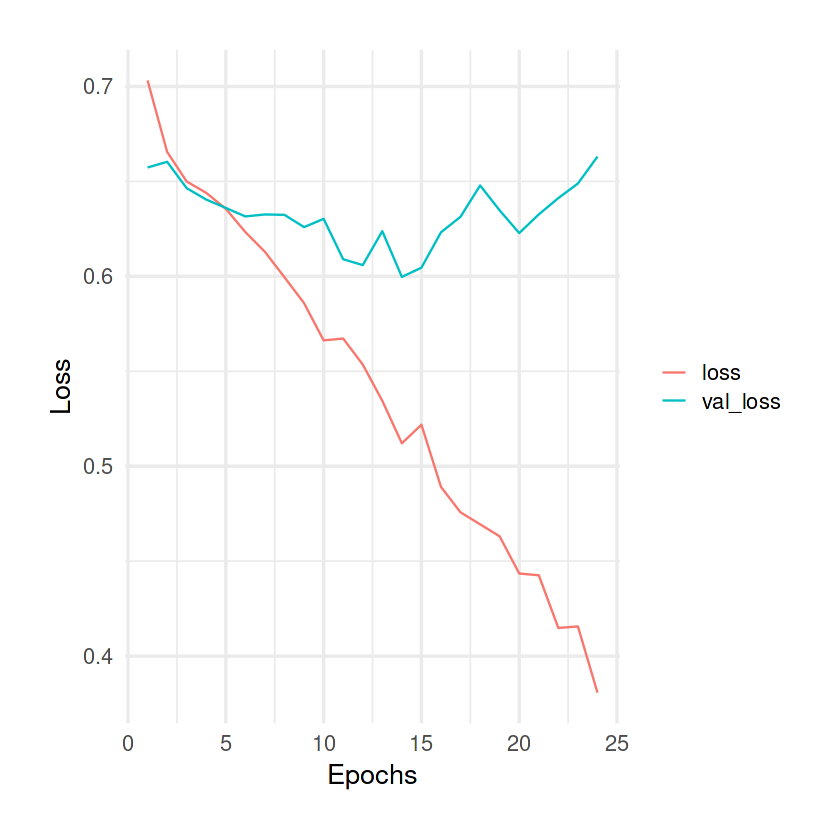

In [47]:
df_loss <- pivot_longer(df, cols = c(loss, val_loss),
                        names_to = "Type", values_to = "Loss")

ggplot(df_loss, aes(x = epoch, y = Loss, color = Type)) +
  geom_line(size = 0.5) +
  labs(x = "Epochs", y = "Loss") +
  theme_minimal(base_size = 16) +
  theme(
    legend.title = element_blank(),
    plot.title = element_blank(),
    plot.margin = margin(30, 30, 30, 30)
  )

In [50]:
file.exists("my_model.h5")


[1] TRUE